# Milestone 2 — Fine-tune YOLO: player / goalkeeper / referee / ball

**Problem from Milestone 1:** the COCO model has one class `person` for players, keepers, referees, coaches and fans, and it often misses the ball.

**Fix:** teach the model new classes by showing it labelled football frames. Fans and coaches are **not labelled** in the dataset, so the model learns to treat them as background and stops boxing them.

Plan of this notebook:
1. Concepts (5 min read)
2. Download a labelled football dataset (Roboflow, 372 images, CC BY 4.0)
3. Look at the labels
4. Train on your RTX 4050
5. Read the training results (loss curves, mAP, confusion matrix)
6. Compare old vs new model on your clip
7. Safety net: pitch mask to drop anything still detected in the stands
8. Save the model and export the annotated video

## 1. Concepts

**Fine-tuning (transfer learning).** YOLO11 already learned general visual features from COCO: edges, textures, human shapes, round objects. We keep those weights as the starting point and continue training on football images, so the last layers re-learn *which* classes exist. Starting from scratch would need tens of thousands of images; fine-tuning works with a few hundred.
> Tabular analogy: like warm-starting a model and continuing to fit on a new, related target instead of fitting from zero.

**What a label is.** Each image has a `.txt` file, one line per object:
```
class_id  x_center  y_center  width  height      (all divided by image size → 0..1)
2         0.4531    0.6120    0.0156  0.0611     ← a player
```

**Training loop words**
| Term | Meaning |
|---|---|
| **epoch** | one pass over all training images |
| **batch** | how many images the GPU processes at once (limited by your 6 GB VRAM) |
| **loss** | how wrong the model is; training lowers it. YOLO reports 3: `box_loss` (box position), `cls_loss` (wrong class), `dfl_loss` (box edge precision) |
| **train / valid / test** | same idea as your tabular splits. `valid` is checked every epoch; `best.pt` = epoch with the best valid score |
| **augmentation** | random flips, colour shifts, *mosaic* (4 images stitched into one) so 372 images look like many more |
| **overfitting** | train loss keeps falling, val loss rises → the model memorises. `patience` stops training early when val stops improving |

**Metrics**
| Metric | Meaning |
|---|---|
| **precision** | of the boxes the model drew, how many were right |
| **recall** | of the real objects, how many the model found |
| **IoU** | overlap between predicted and true box (0 = none, 1 = perfect) |
| **mAP50** | average precision when a box counts as correct at IoU ≥ 0.5. The main "is it good" number |
| **mAP50-95** | same, averaged over stricter IoU 0.5…0.95. Lower, measures box tightness |

Expect high mAP for **player**, decent for **referee** and **goalkeeper**, and the lowest for **ball** (tiny objects are hard).

## 2. Setup

In [1]:
import sys, os, shutil, time
from pathlib import Path
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, supervision as sv
from ultralytics import YOLO

ROOT = Path.cwd().parent                      # run Jupyter from notebooks/
DATA_DIR = ROOT / "data" / "datasets"
MODELS = ROOT / "models"
for p in [DATA_DIR, MODELS, ROOT / "outputs"]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"   # 0 = first GPU
WORKERS = 0 if os.name == "nt" else 4                 # Windows + Jupyter: 0 avoids dataloader hangs
print("ROOT:", ROOT)
print("GPU:", torch.cuda.get_device_name(0) if DEVICE == 0 else "none",
      "| VRAM GB:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if DEVICE == 0 else "-")

ROOT: d:\codes\football pretrained
GPU: NVIDIA GeForce RTX 4050 Laptop GPU | VRAM GB: 6.4


## 3. Download the dataset

Dataset: **football-players-detection** on Roboflow Universe — https://universe.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc
(broadcast frames, classes `ball`, `goalkeeper`, `player`, `referee`, licence CC BY 4.0).

1. Make a free account at roboflow.com → Settings → **API Keys** → copy your private key.
2. Paste it below. **Never commit this key to GitHub** — later we'll move it to a `.env` file.

**If `pip install roboflow` fails** (it can lag behind new Python versions like 3.14): on the dataset page click
*Dataset → Download Dataset → Format: YOLOv11 → Download zip*, unzip it into `data/datasets/football-players/` and skip to the next cell.

In [2]:
%pip install -q roboflow

Note: you may need to restart the kernel to use updated packages.


In [3]:
DS = DATA_DIR / "football-players"

if not (DS / "data.yaml").exists():
    from roboflow import Roboflow
    API_KEY = "YOUR_ROBOFLOW_KEY"   # never commit a real key
    rf = Roboflow(api_key=API_KEY)
    project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
    try:   # use the newest version
        VERSION = max(int(str(v.version).rstrip("/").split("/")[-1]) for v in project.versions())
    except Exception:
        VERSION = 20   # fallback: number shown on the Universe page
    print("Downloading version", VERSION)
    ds = project.version(VERSION).download("yolov11", location=str(DS))

print(sorted(p.name for p in DS.iterdir()))

['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'data_fixed.yaml', 'test', 'train', 'valid']


Roboflow's `data.yaml` uses relative paths that often break (`Dataset images not found`).
We rewrite it with an absolute `path:` so it works from any folder.

In [4]:
import yaml
cfg = yaml.safe_load(open(DS / "data.yaml"))
print("classes:", cfg["names"])

fixed = {
    "path": str(DS.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": cfg["names"],
}
DATA_YAML = DS / "data_fixed.yaml"
yaml.safe_dump(fixed, open(DATA_YAML, "w"))

for split in ["train", "valid", "test"]:
    n = len(list((DS / split / "images").glob("*")))
    print(f"{split:5s}: {n} images")

classes: ['ball', 'goalkeeper', 'player', 'referee']
train: 298 images
valid: 49 images
test : 25 images


## 4. Look at the labels before training
Always check the data first. Bad labels → bad model, no matter how long you train.

In [5]:
NAMES = cfg["names"] if isinstance(cfg["names"], list) else [cfg["names"][k] for k in sorted(cfg["names"])]

rows = []
for lbl in (DS / "train" / "labels").glob("*.txt"):
    for line in open(lbl):
        c, xc, yc, w, h = line.split()[:5]
        rows.append(dict(img=lbl.stem, cls=NAMES[int(c)], w=float(w), h=float(h)))
labels = pd.DataFrame(rows)

print("objects per class (train):")
print(labels.cls.value_counts())
print("\nper image, average:")
print((labels.groupby(["img", "cls"]).size().unstack(fill_value=0)).mean().round(2))

objects per class (train):
cls
player        5955
referee        690
ball           258
goalkeeper     230
Name: count, dtype: int64

per image, average:
cls
ball           0.87
goalkeeper     0.77
player        19.98
referee        2.32
dtype: float64


Note the **imbalance**: ~20 players per image, ~1 goalkeeper, ~2–3 referees, ≤1 ball.
Rare classes get fewer learning examples → expect lower scores for goalkeeper and ball.

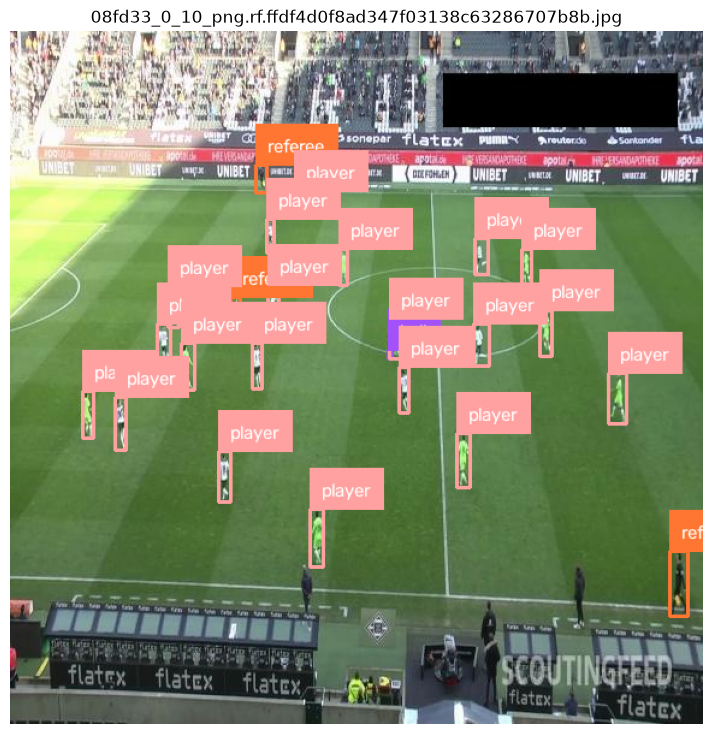

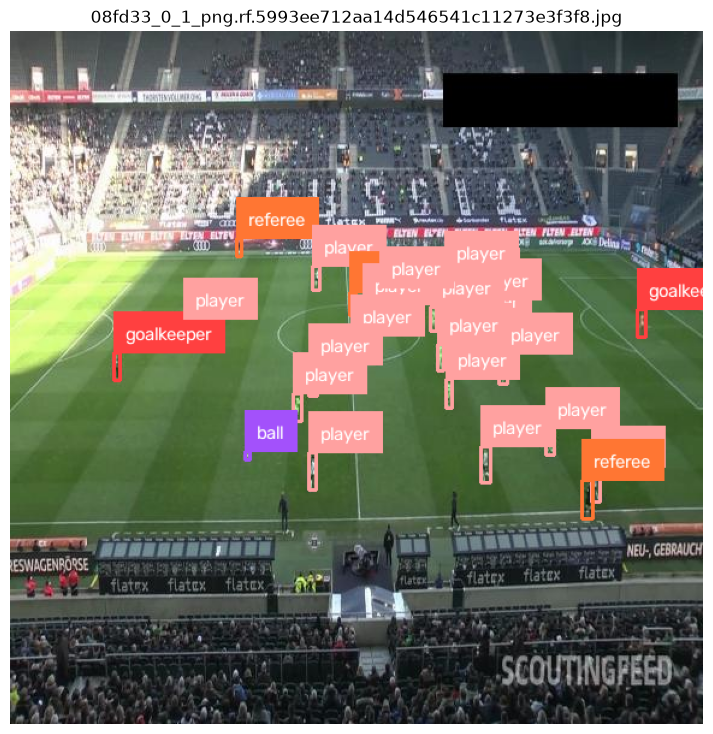

In [6]:
def show_labelled(img_path):
    img = cv2.imread(str(img_path)); H, W = img.shape[:2]
    lbl = img_path.parent.parent / "labels" / (img_path.stem + ".txt")
    xyxy, cls = [], []
    for line in open(lbl):
        c, xc, yc, w, h = map(float, line.split()[:5])
        xyxy.append([(xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H]); cls.append(int(c))
    det = sv.Detections(xyxy=np.array(xyxy), class_id=np.array(cls))
    out = sv.BoxAnnotator(color=sv.ColorPalette.DEFAULT, thickness=2).annotate(img.copy(), det)
    out = sv.LabelAnnotator(text_scale=0.5).annotate(out, det, labels=[NAMES[c] for c in cls])
    plt.figure(figsize=(16, 9)); plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title(img_path.name); plt.show()

train_imgs = sorted((DS / "train" / "images").glob("*"))
for p in train_imgs[:2]:
    show_labelled(p)

👀 Check: fans in the stands have **no box**. That's exactly how the model learns to ignore them.

## 5. Train

Settings chosen for an **RTX 4050 Laptop (6 GB)**:

| Setting | Value | Why |
|---|---|---|
| `model` | `yolo11s.pt` | small enough for 6 GB at 1280; `m` fits only with a tiny batch |
| `imgsz` | 1280 | the ball needs resolution (you saw this in 5a) |
| `batch` | -1 | **AutoBatch**: ultralytics measures your VRAM and picks the largest safe batch |
| `epochs` | 60 | with `patience=20` it stops early if valid mAP stops improving |
| `cache` | True | keeps decoded images in RAM → much faster epochs |
| `workers` | 0 on Windows | avoids a known multiprocessing hang inside Jupyter |

Expect roughly **20–40 min**. Progress bars print per epoch. If you get `CUDA out of memory`, set `batch=4` (or `2`) instead of `-1`.
Close games/Chrome tabs using the GPU while training.

Colab alternative (free T4, 16 GB): upload this notebook and the dataset folder, and you can use `yolo11m.pt` with `batch=8`.

In [7]:
RUN_NAME = "players_y11s_1280"

model = YOLO("yolo11s.pt")          # start from COCO-pretrained weights = fine-tuning
t0 = time.time()
results = model.train(
    data=str(DATA_YAML),
    imgsz=1280,
    epochs=60,
    patience=20,
    batch=4,
    device=DEVICE,
    workers=WORKERS,
    cache=True,
    project=str(ROOT / "runs"),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    seed=42,
)
print(f"training took {(time.time() - t0) / 60:.1f} min")
RUN = ROOT / "runs" / RUN_NAME
BEST = RUN / "weights" / "best.pt"
print("best weights:", BEST)

New https://pypi.org/project/ultralytics/8.4.175 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.174  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\codes\football pretrained\data\datasets\football-players\data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rati

## 6. Read the results

### 6a. Loss and metric curves (`results.png`)
- **train/*_loss** should go down smoothly.
- **val/*_loss** should go down then flatten. If it climbs while train loss falls → overfitting.
- **metrics/mAP50(B)** should rise and plateau.

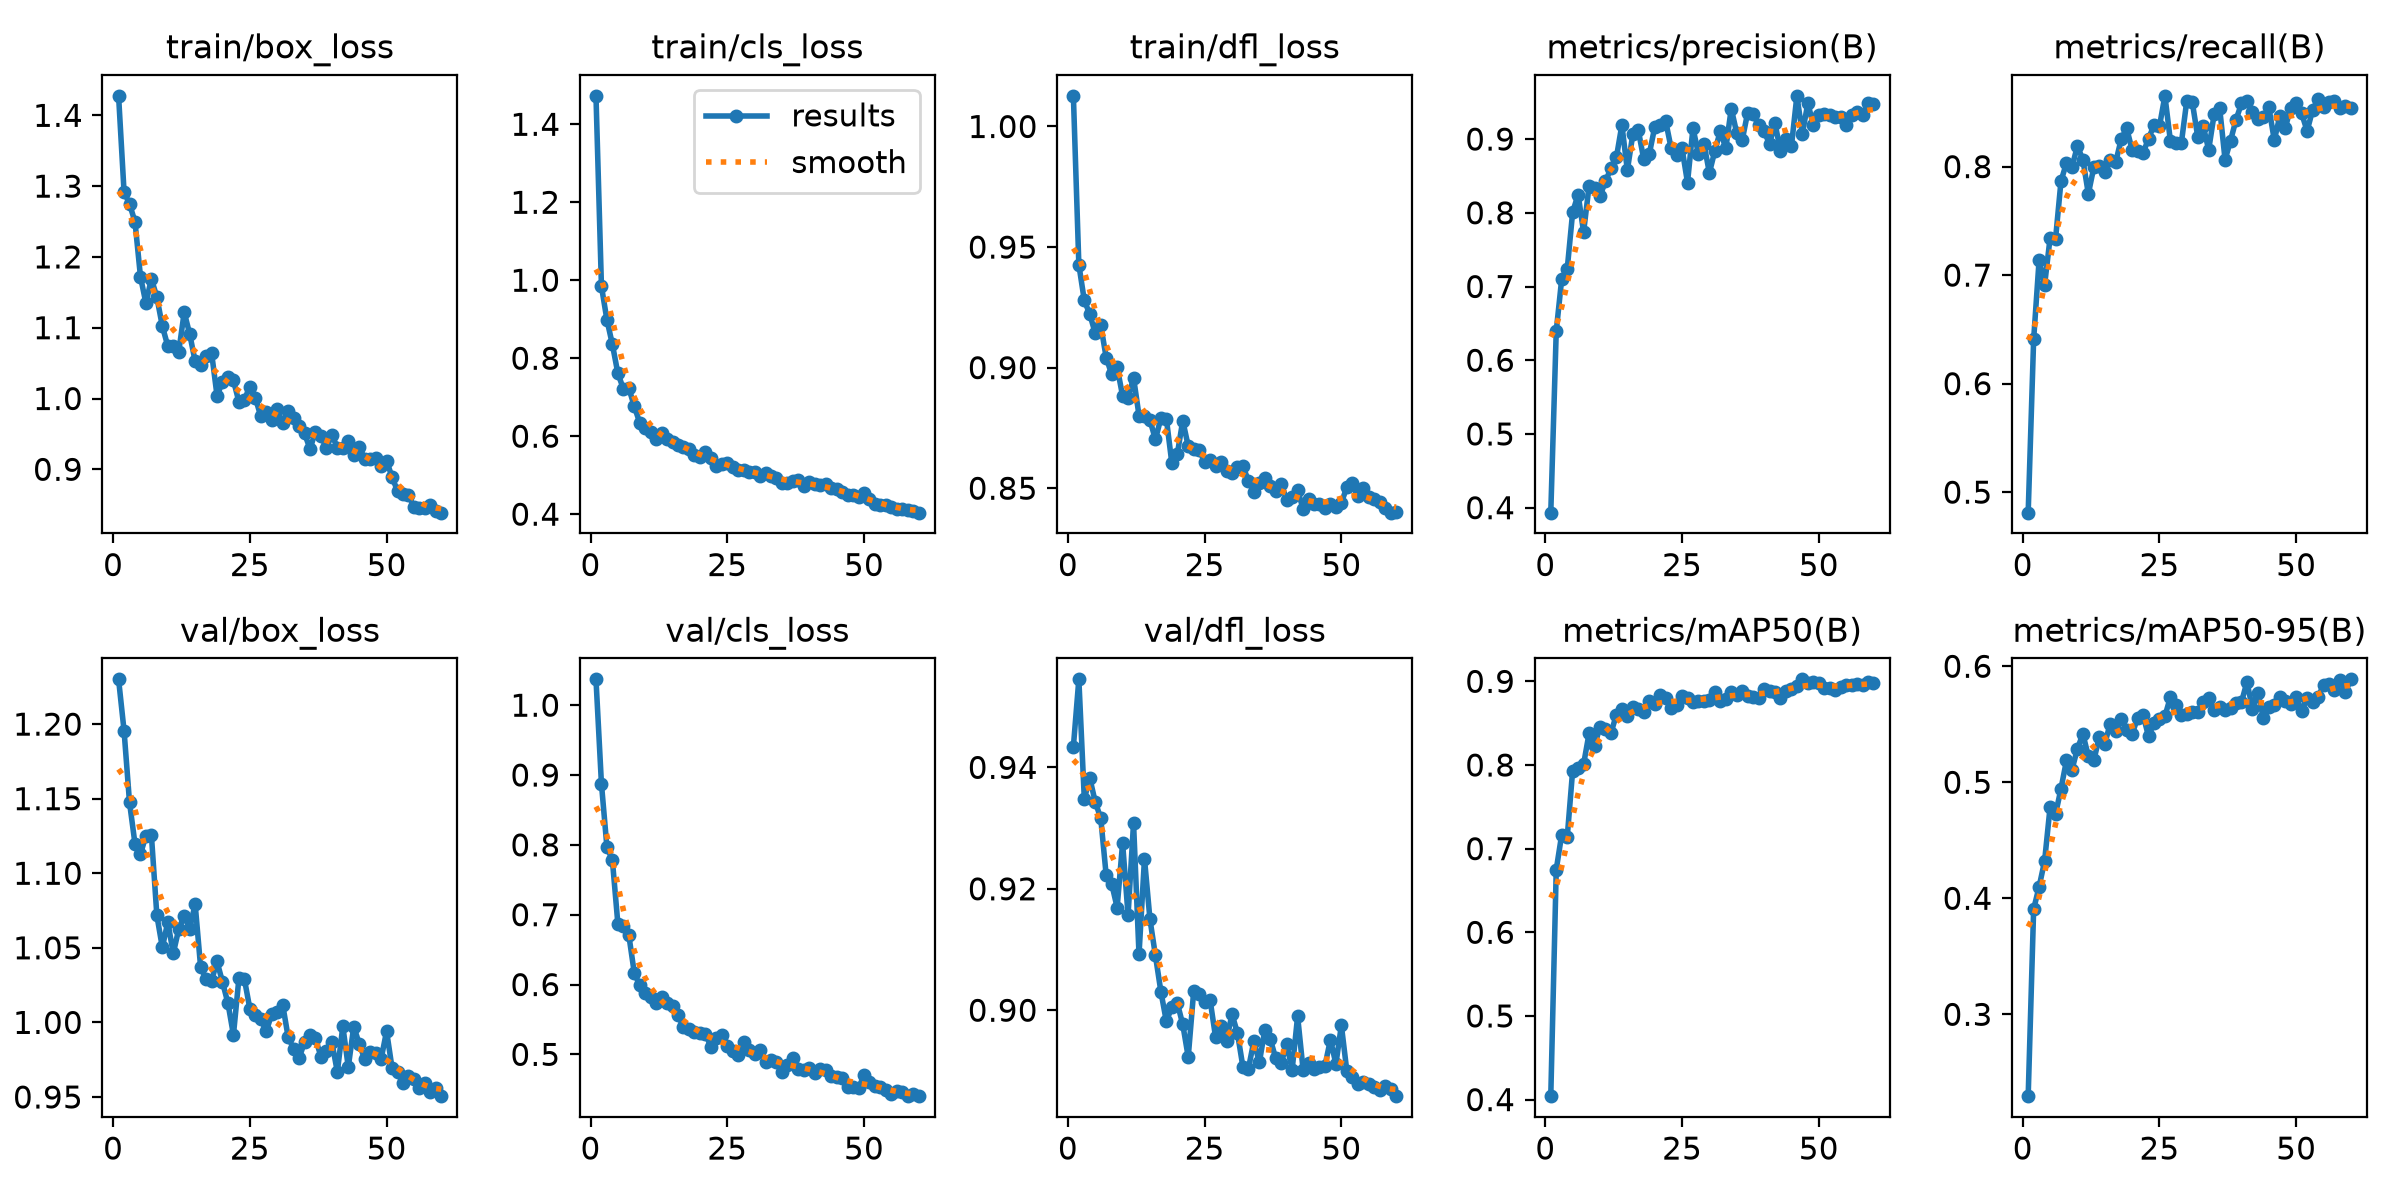

In [8]:
from IPython.display import Image, display
display(Image(filename=str(RUN / "results.png"), width=1100))

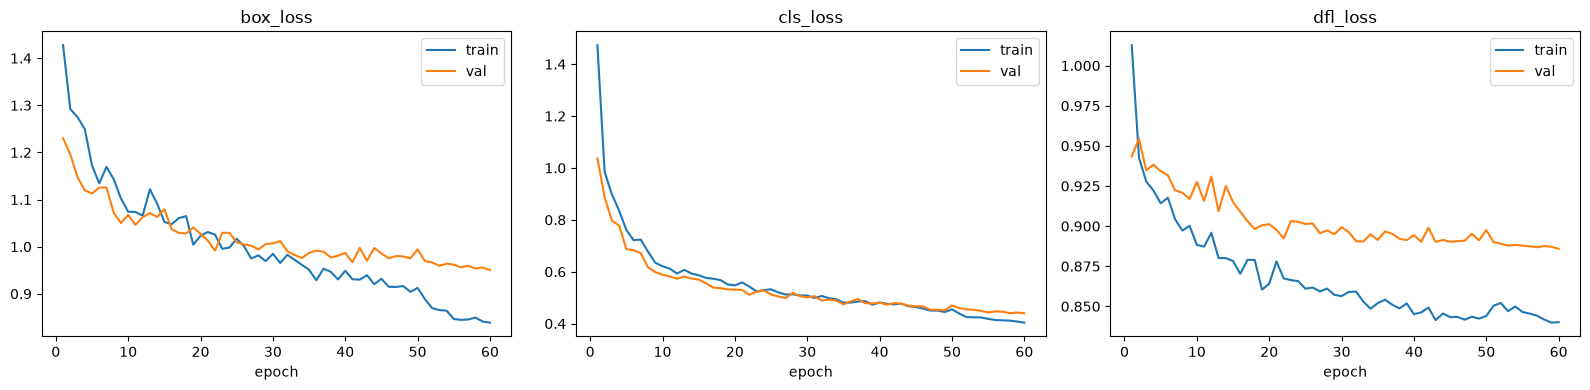

best epoch 47: mAP50=0.902  mAP50-95=0.573


In [9]:
hist = pd.read_csv(RUN / "results.csv"); hist.columns = hist.columns.str.strip()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, k in zip(ax, ["box_loss", "cls_loss", "dfl_loss"]):
    a.plot(hist.epoch, hist[f"train/{k}"], label="train"); a.plot(hist.epoch, hist[f"val/{k}"], label="val")
    a.set_title(k); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()
best_row = hist.loc[hist["metrics/mAP50(B)"].idxmax()]
print(f"best epoch {int(best_row.epoch)}: mAP50={best_row['metrics/mAP50(B)']:.3f}  mAP50-95={best_row['metrics/mAP50-95(B)']:.3f}")

### 6b. Per-class scores on the **test** set (images never used for training or model selection)

In [10]:
ft = YOLO(str(BEST))
m = ft.val(data=str(DATA_YAML), split="test", imgsz=1280, device=DEVICE, workers=WORKERS, plots=True,
           project=str(ROOT / "runs"), name=RUN_NAME + "_test", exist_ok=True, verbose=False)

per_class = pd.DataFrame({
    "class": [ft.names[i] for i in m.box.ap_class_index],
    "precision": m.box.p, "recall": m.box.r,
    "mAP50": m.box.ap50, "mAP50-95": m.box.ap,
}).round(3)
per_class

Ultralytics 8.4.174  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.00.0 ms, read: 6.81.2 MB/s, size: 55.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\codes\football pretrained\data\datasets\football-players\test\labels... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 353.9it/s 0.1s
val: New cache created: D:\codes\football pretrained\data\datasets\football-players\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3it/s 1.5s2.8s
                   all         25        598      0.942      0.853      0.908      0.609
Speed: 1.8ms preprocess, 33.9ms inference, 0.0ms loss, 4.5ms postprocess per image
Results save

,class,precision,recall,mAP50,mAP50-95
0,ball,0.928,0.541,0.719,0.293
1,goalkeeper,0.898,0.923,0.947,0.711
2,player,0.974,0.984,0.993,0.761
3,referee,0.967,0.964,0.974,0.671


### 6c. Confusion matrix
Rows/columns = true vs predicted class. Off-diagonal cells show **which classes get mixed up** (typically goalkeeper ↔ player, referee ↔ player, and ball ↔ background = missed).

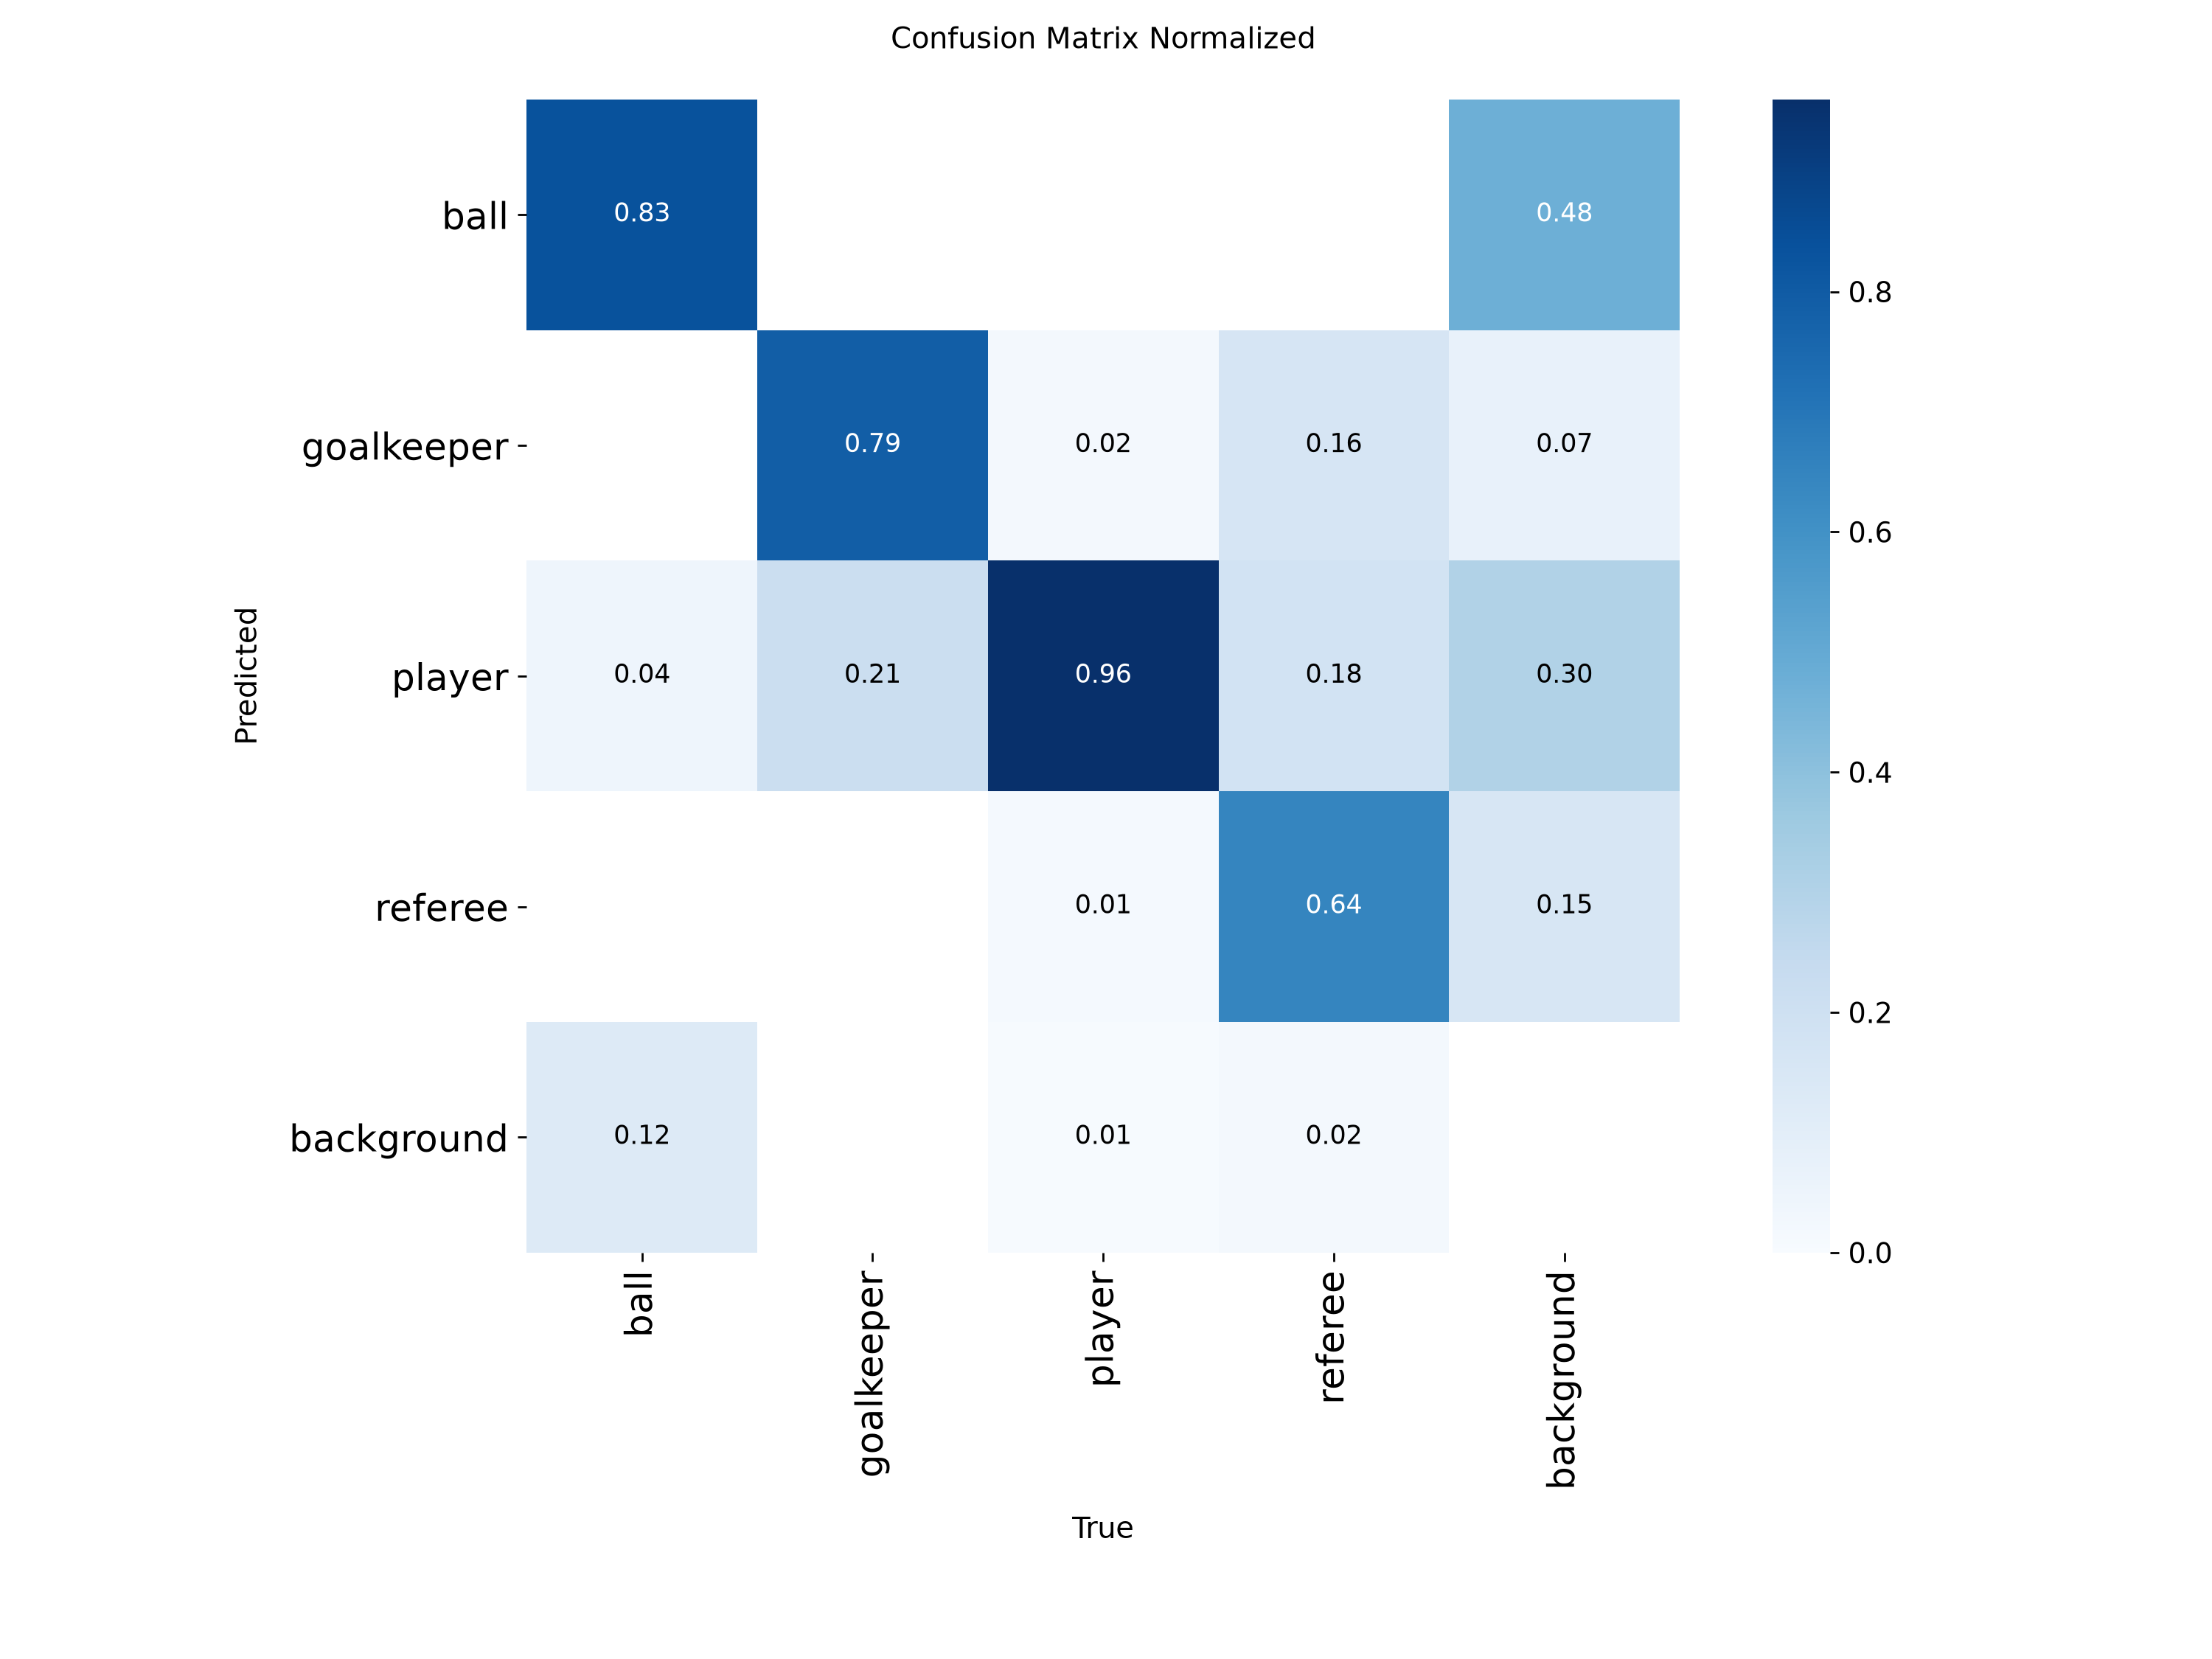

In [11]:
display(Image(filename=str(ROOT / "runs" / (RUN_NAME + "_test") / "confusion_matrix_normalized.png"), width=700))

## 7. Old vs new on your own clip

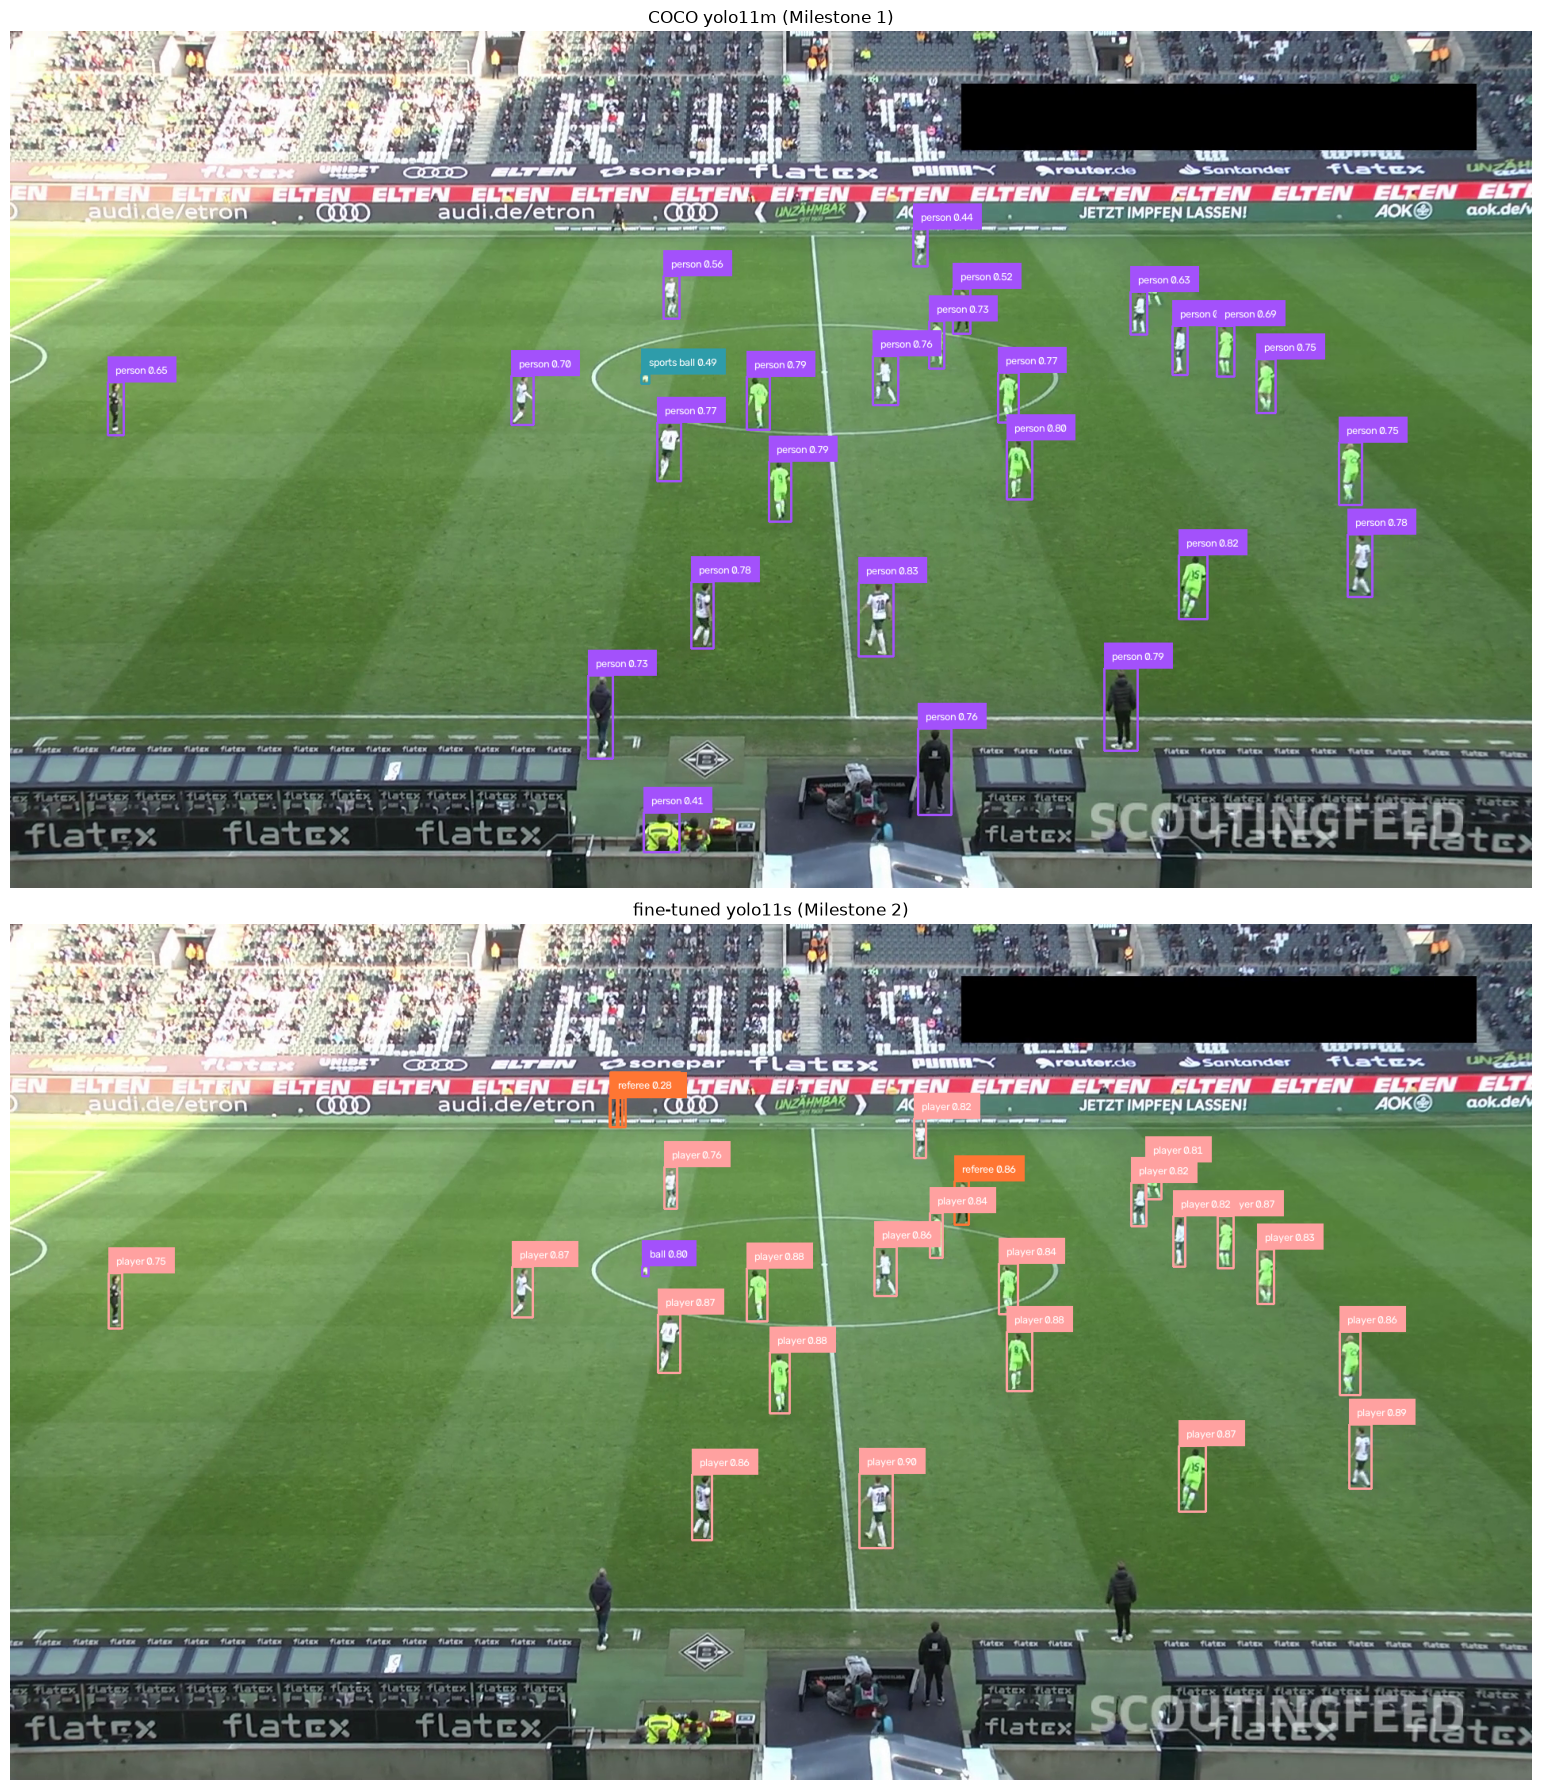

old: {'person': 25, 'sports ball': 1}
new: {'player': 21, 'referee': 4, 'ball': 1}


In [12]:
VIDEO = ROOT / "data" / "raw" / "08fd33_0.mp4"

def read_frame(path, idx):
    cap = cv2.VideoCapture(str(path)); cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, f = cap.read(); cap.release(); assert ok, f"could not read frame {idx} of {path}"
    return f

coco = YOLO("yolo11m.pt")
frame = read_frame(VIDEO, 200)

det_old = sv.Detections.from_ultralytics(coco.predict(frame, classes=[0, 32], conf=0.25, imgsz=1280, device=DEVICE, verbose=False)[0])
det_new = sv.Detections.from_ultralytics(ft.predict(frame, conf=0.25, imgsz=1280, device=DEVICE, verbose=False)[0])

def annotate(img, d):
    labels = [f"{n} {c:.2f}" for n, c in zip(d.data["class_name"], d.confidence)]
    out = sv.BoxAnnotator(thickness=2).annotate(img.copy(), d)
    return sv.LabelAnnotator(text_scale=0.45).annotate(out, d, labels=labels)

fig, ax = plt.subplots(2, 1, figsize=(16, 18))
for a, (t, d) in zip(ax, [("COCO yolo11m (Milestone 1)", det_old), ("fine-tuned yolo11s (Milestone 2)", det_new)]):
    a.imshow(cv2.cvtColor(annotate(frame, d), cv2.COLOR_BGR2RGB)); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

print("old:", pd.Series(det_old.data["class_name"]).value_counts().to_dict())
print("new:", pd.Series(det_new.data["class_name"]).value_counts().to_dict())

In [13]:
# Same comparison over 40 frames: how often is the ball found, and are fans gone?
idxs = np.linspace(0, int(cv2.VideoCapture(str(VIDEO)).get(cv2.CAP_PROP_FRAME_COUNT)) - 1, 40, dtype=int)
sample = [read_frame(VIDEO, i) for i in idxs]
BALL_ID = [k for k, v in ft.names.items() if v == "ball"][0]

def summarise(model, ball_id, classes=None):
    ds = [sv.Detections.from_ultralytics(r) for r in
          model.predict(sample, classes=classes, conf=0.25, imgsz=1280, device=DEVICE, verbose=False)]
    return dict(ball_found_pct=100 * np.mean([(d.class_id == ball_id).any() for d in ds]),
                boxes_per_frame=np.mean([len(d) for d in ds]))

pd.DataFrame([dict(model="COCO yolo11m", **summarise(coco, 32, [0, 32])),
              dict(model="fine-tuned yolo11s", **summarise(ft, BALL_ID))]).round(1)

,model,ball_found_pct,boxes_per_frame
0,COCO yolo11m,47.5,26.2
1,fine-tuned yolo11s,70.0,24.2


## 8. Safety net — pitch mask

Fine-tuning removes most fans and coaches, but a few may still appear (a coach in the technical area, a ball boy, a steward near the line).
A cheap extra filter: **keep only boxes whose feet are on the pitch**.

How it works:
1. Convert the frame to HSV colour space (Hue = colour type, Saturation, Value = brightness). Grass is a narrow hue band, easy to threshold.
2. Mask = pixels whose hue is green.
3. Clean the mask (morphological close/open), take the biggest green region and fill its convex hull, so players *standing on* the grass count as "on the pitch" even though their shirts aren't green.
4. For each box, test the bottom-centre point (the feet).

This is classic computer vision, no deep learning. It's fast but sensitive to lighting, shadows and very worn pitches, so treat it as a backup, not the main fix.

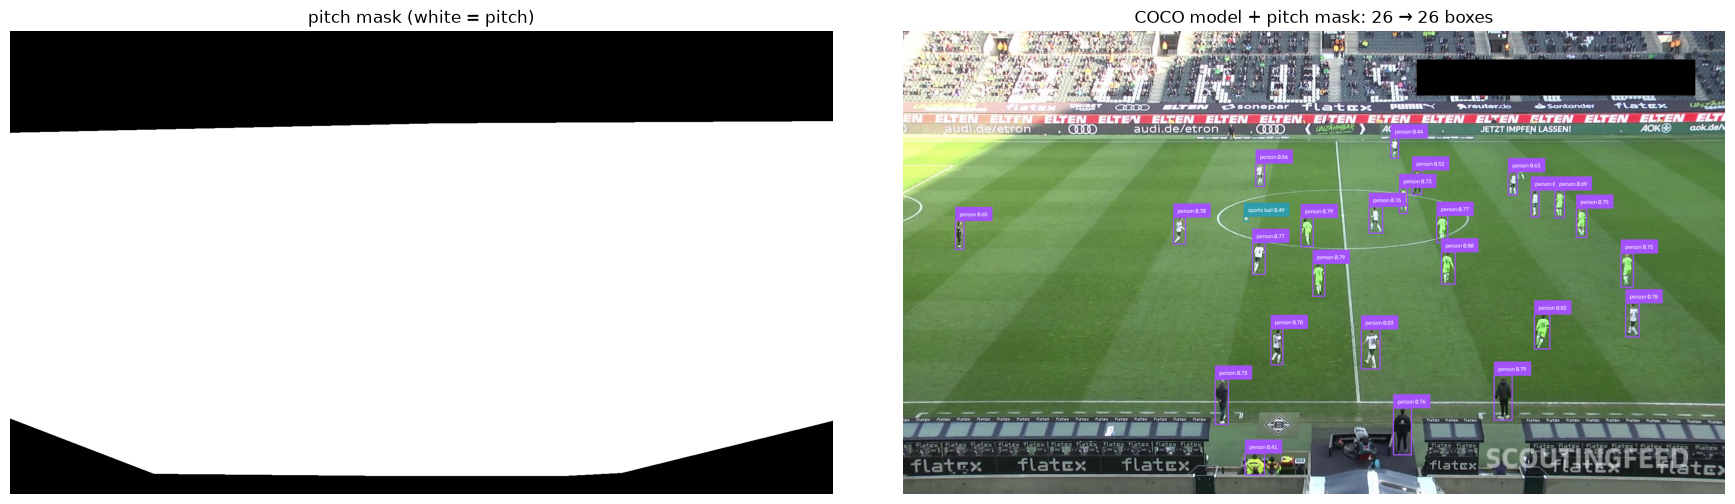

In [14]:
def pitch_mask(frame, lower=(30, 40, 40), upper=(90, 255, 255)):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    green = cv2.inRange(hsv, np.array(lower), np.array(upper))
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
    green = cv2.morphologyEx(green, cv2.MORPH_CLOSE, k)
    green = cv2.morphologyEx(green, cv2.MORPH_OPEN, k)
    cnts, _ = cv2.findContours(green, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros(frame.shape[:2], np.uint8)
    if cnts:
        hull = cv2.convexHull(max(cnts, key=cv2.contourArea))
        cv2.fillPoly(mask, [hull], 255)
    return mask

def keep_on_pitch(det, mask, keep_classes=None):
    # keep_classes: class ids exempt from the test (e.g. the ball can be in the air)
    feet = det.get_anchors_coordinates(sv.Position.BOTTOM_CENTER).astype(int)
    h, w = mask.shape
    xs, ys = feet[:, 0].clip(0, w - 1), feet[:, 1].clip(0, h - 1)
    on = mask[ys, xs] > 0
    if keep_classes is not None:
        on |= np.isin(det.class_id, keep_classes)
    return det[on]

mask = pitch_mask(frame)
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].imshow(mask, cmap="gray"); ax[0].set_title("pitch mask (white = pitch)"); ax[0].axis("off")
old_filtered = keep_on_pitch(det_old, mask, keep_classes=[32])
ax[1].imshow(cv2.cvtColor(annotate(frame, old_filtered), cv2.COLOR_BGR2RGB)); ax[1].axis("off")
ax[1].set_title(f"COCO model + pitch mask: {len(det_old)} → {len(old_filtered)} boxes")
plt.tight_layout(); plt.show()

Tune the green range if the mask looks wrong for your clip: print `cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)[y, x]` at a grass pixel to see its H, S, V values.

## 9. Save the model and render the clip with the new classes

In [15]:
MODEL_PATH = MODELS / "football_yolo11s_1280.pt"
shutil.copy(BEST, MODEL_PATH)
print("saved", MODEL_PATH)

OUT = ROOT / "outputs" / f"m2_{VIDEO.stem}_finetuned.mp4"
vinfo = sv.VideoInfo.from_video_path(str(VIDEO))
counts = []
with sv.VideoSink(str(OUT), vinfo) as sink:
    for i, f in enumerate(sv.get_video_frames_generator(str(VIDEO))):
        d = sv.Detections.from_ultralytics(ft.predict(f, conf=0.25, imgsz=1280, device=DEVICE, verbose=False)[0])
        d = keep_on_pitch(d, pitch_mask(f), keep_classes=[BALL_ID])
        counts.append({"frame": i, **pd.Series(d.data["class_name"]).value_counts().to_dict()})
        sink.write_frame(annotate(f, d))
counts = pd.DataFrame(counts).fillna(0)
print("saved", OUT)
ball_pct = 100 * (counts["ball"] > 0).mean() if "ball" in counts else 0.0
print(f"ball visible in {ball_pct:.1f}% of frames")
counts.drop(columns="frame").mean().round(2)

saved d:\codes\football pretrained\models\football_yolo11s_1280.pt
saved d:\codes\football pretrained\outputs\m2_08fd33_0_finetuned.mp4
ball visible in 70.8% of frames


player        20.89
referee        2.51
goalkeeper     0.19
ball           0.80
dtype: float64

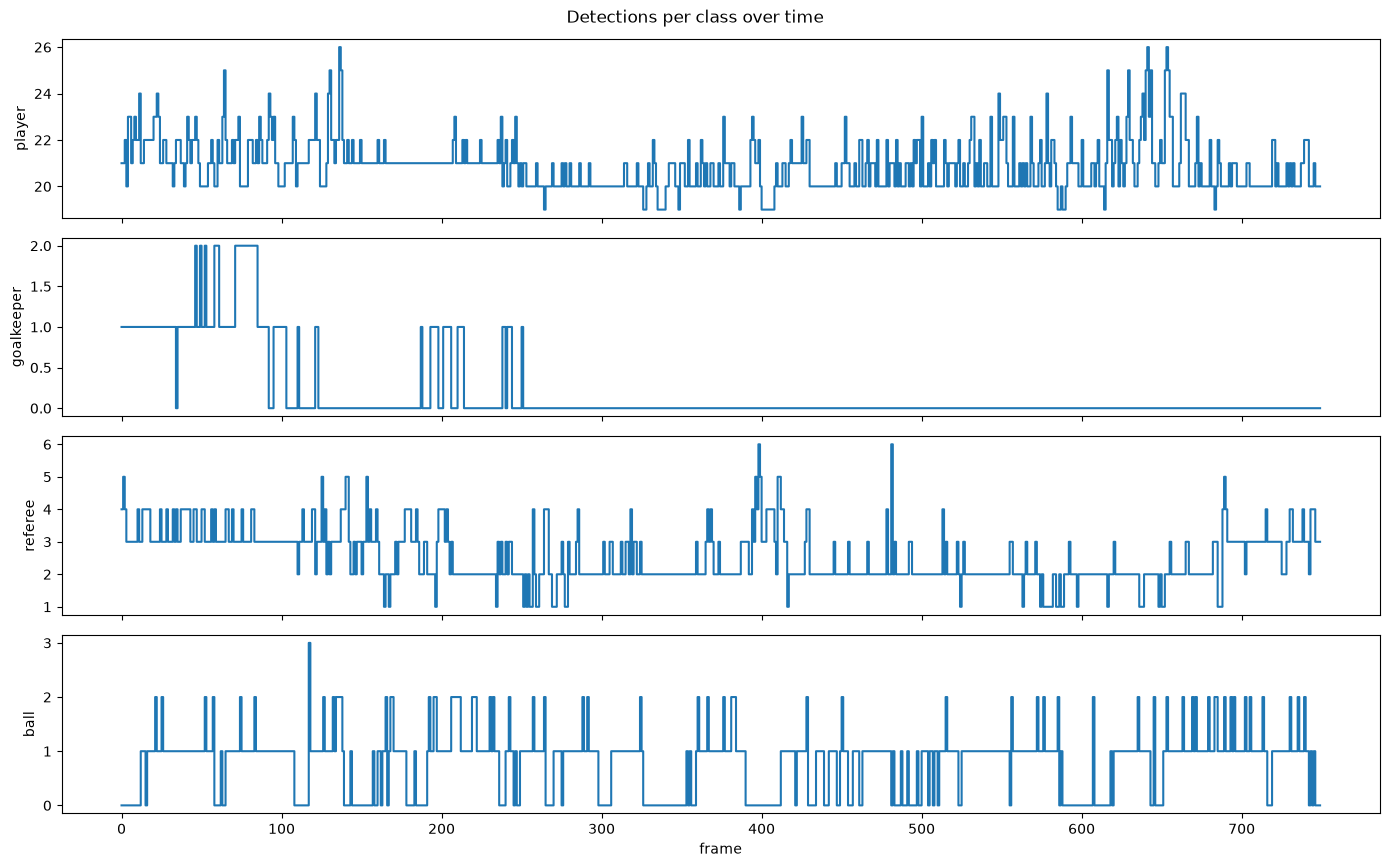

In [16]:
cols = [c for c in ["player", "goalkeeper", "referee", "ball"] if c in counts]
fig, ax = plt.subplots(len(cols), 1, figsize=(14, 2.2 * len(cols)), sharex=True)
for a, c in zip(np.atleast_1d(ax), cols):
    a.step(counts.frame, counts[c], where="post"); a.set_ylabel(c)
plt.xlabel("frame"); plt.suptitle("Detections per class over time"); plt.tight_layout(); plt.show()

## Pitfalls you'll notice
- **Class flicker:** the same keeper is `goalkeeper` in one frame and `player` in the next. One frame alone can't fix this. In **Milestone 3** each person gets a track ID and we take the *majority class over the track*.
- **Referee vs dark kit:** if a team wears black, referee/player confusion rises. Check it in the confusion matrix.
- **Ball still missed sometimes:** blur, occlusion, ball in the air. **Milestone 5** fills gaps by interpolating between frames.
- **Different clip, different look:** 372 images from a few matches. A clip with new kits, lighting or camera angle scores lower. Fix: label 50–100 frames from your own footage (the frames you saved in M1) and train again.
- **Never judge on training images.** Use the test split or your own clip.

## ✅ Before Milestone 3, make sure you can answer
1. What does fine-tuning reuse from the COCO model, and what changes?
2. Why do fans disappear after fine-tuning even though we never told the model "fan"?
3. What do precision, recall and mAP50 mean? Which class scored lowest, and why?
4. How do you spot overfitting in `results.png`?
5. Why is the pitch mask only a backup?
6. Your numbers: test mAP50 per class, and ball-visible % before (M1) vs after.